# CsI(Tl)–SiPM：平均波形、PID 中心/带宽与短尺度起伏的联合约束

2026-10-29。先提交并推送英文提交 `f7a840c`（[尾部研究](codex_0001_csi_co_tail_refit.ipynb)），再开展本轮。
上一轮改善了 Co 的尾部，却留下 Am 平均时间带宽偏窄、α 慢时间触及15 μs边界的问题。

本轮固定 **4、6、8.4386 μs** 三组α慢时间，在原前60%实验数据中联合约束中心、三种PID宽度/协方差、均ADC与短尺度起伏。
先运行 **96000次独立母衰变** 做三组完整Geant4校准，再对同一批母事件做原生噪声重放；这些重放不增加独立统计量。
按预先冻结的目标选择一组后，再运行 **32000次新种子母衰变** 做验证。所有展示的模拟ADC都来自原生C++输出。

这里的“联合”是分阶段校准与共同评价，不是一个包含所有装置参数的全局似然拟合。未把实测波形注入模拟，也未给PID分数直接加宽。


In [1]:
from pathlib import Path
import json, sys
import numpy as np
from IPython.display import display, Markdown, Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/joint_constraints_20261029'
def read(p):return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
def nums(v):return ' / '.join(f'{x:.3f}' for x in v)
def ci(m,field,j,block='64'):
    lo,hi=m['uncertainty_by_data_block'][block][field][j]['estimate95']
    return f'[{lo:.3f}, {hi:.3f}]'
d=read(OUT/'design.json');s=read(OUT/'selection.json');r=read(OUT/'assessment.json');decision=read(OUT/'decision.json')
print('Python/NumPy:',sys.version.split()[0],np.__version__)
rows=[]
for stage in ['profile','calibration','validation']:
    p=read(OUT/stage/'protocol.json')
    for key,e in p['entries'].items():
        x=read(OUT/stage/'extraction'/f'{key}.json')
        v=read((PROJECT/e['path']).with_name(Path(e['path']).stem+'_validation.json'))
        rows.append([stage,key,e['events'],e['seed'],x['n_common'],x['common_truth_counts'],v['passed']])
display(Markdown(table(['阶段','场景','母事件/重放数','种子','共同Q事件','α/γ/电子/混合/其他祖先','物理检查'],rows)))
print('独立母事件总数:',r['calibration_independent_mothers']+r['new_independent_mothers'])

Python/NumPy: 3.13.5 2.5.4
独立母事件总数: 128000


|阶段|场景|母事件/重放数|种子|共同Q事件|α/γ/电子/混合/其他祖先|物理检查|
|---|---|---|---|---|---|---|
|profile|a4000_run3_Co60|8000|401029003|293|[0, 293, 0, 0, 0]|True|
|profile|a4000_run12_Am241|24000|401029012|189|[189, 0, 0, 0, 0]|True|
|profile|a6000_run3_Co60|8000|401030003|306|[0, 306, 0, 0, 0]|True|
|profile|a6000_run12_Am241|24000|401030012|183|[183, 0, 0, 0, 0]|True|
|profile|a8439_run3_Co60|8000|401031003|252|[0, 251, 1, 0, 0]|True|
|profile|a8439_run12_Am241|24000|401031012|175|[175, 0, 0, 0, 0]|True|
|calibration|a4000_run3_Co60|8000|401029003|297|[0, 297, 0, 0, 0]|True|
|calibration|a4000_run12_Am241|24000|401029012|186|[186, 0, 0, 0, 0]|True|
|calibration|a6000_run3_Co60|8000|401030003|303|[0, 303, 0, 0, 0]|True|
|calibration|a6000_run12_Am241|24000|401030012|180|[180, 0, 0, 0, 0]|True|
|calibration|a8439_run3_Co60|8000|401031003|256|[0, 255, 1, 0, 0]|True|
|calibration|a8439_run12_Am241|24000|401031012|179|[179, 0, 0, 0, 0]|True|
|validation|run3_Co60|8000|401029903|276|[0, 276, 0, 0, 0]|True|
|validation|run12_Am241|24000|401029912|194|[194, 0, 0, 0, 0]|True|

## 1. 有限记录窗与α慢分量的条件参数族

积分门为−40至3000 ns，原记录总长约4992 ns。长时间成分的τ、份额、产额可以在此窗口内相互补偿，因此本轮不再把15 μs边界最优值作为材料测量值。
4/6/8.44 μs是预设的敏感性选项，**不是文献确定范围、置信区间或已经测定的CsI衰减常数**。

每组拟合电子快/慢τ、α快τ和共同RC，两个快分量份额用前60%的平均时间约束求解。
叠加旧原生MC与解析卷积的固定平滑差，只用于提出参数；该差不进入原生数字化。
每组3个起点，保留全部结果，选择收敛且解析目标最小的起点。

共同光产额乘子与α相对归一化用于保持解析3 μs门积分；无逐事件幅度缩放。
SiPM PDE=0.3、被动信号传输=0.5、SPE2/29 ns、几何、前触发噪声和事件方差CV均沿用上一阶段的条件假设。
源距、求和电路等信息仍不完整。下表“有效α相对归一化”不能直接称为实验淬灭因子。
继承配置中的 `tail_refit`、`npe_profile` 记录仅表示历史；本轮参数与用途以实际配置、`joint_constraints`、`design.json` 和 `selection.json` 为准。


Co60 4与8.44 μs提议曲线之间的NRMSE/实测峰: 0.0094%
Am241 4与8.44 μs提议曲线之间的NRMSE/实测峰: 0.0928%


|组|α慢τ/μs|电子τ/ns|α快τ/ns|共同RC/ns|有效α相对归一化|解析目标|
|---|---|---|---|---|---|---|
|a4000|4.0000|127.046 / 771.049|730.32|129.85|0.8029|13.8440|
|a6000|6.0000|128.332 / 771.191|764.90|128.79|0.8914|13.8375|
|a8439|8.4386|129.050 / 771.281|782.37|128.21|0.9985|13.8387|

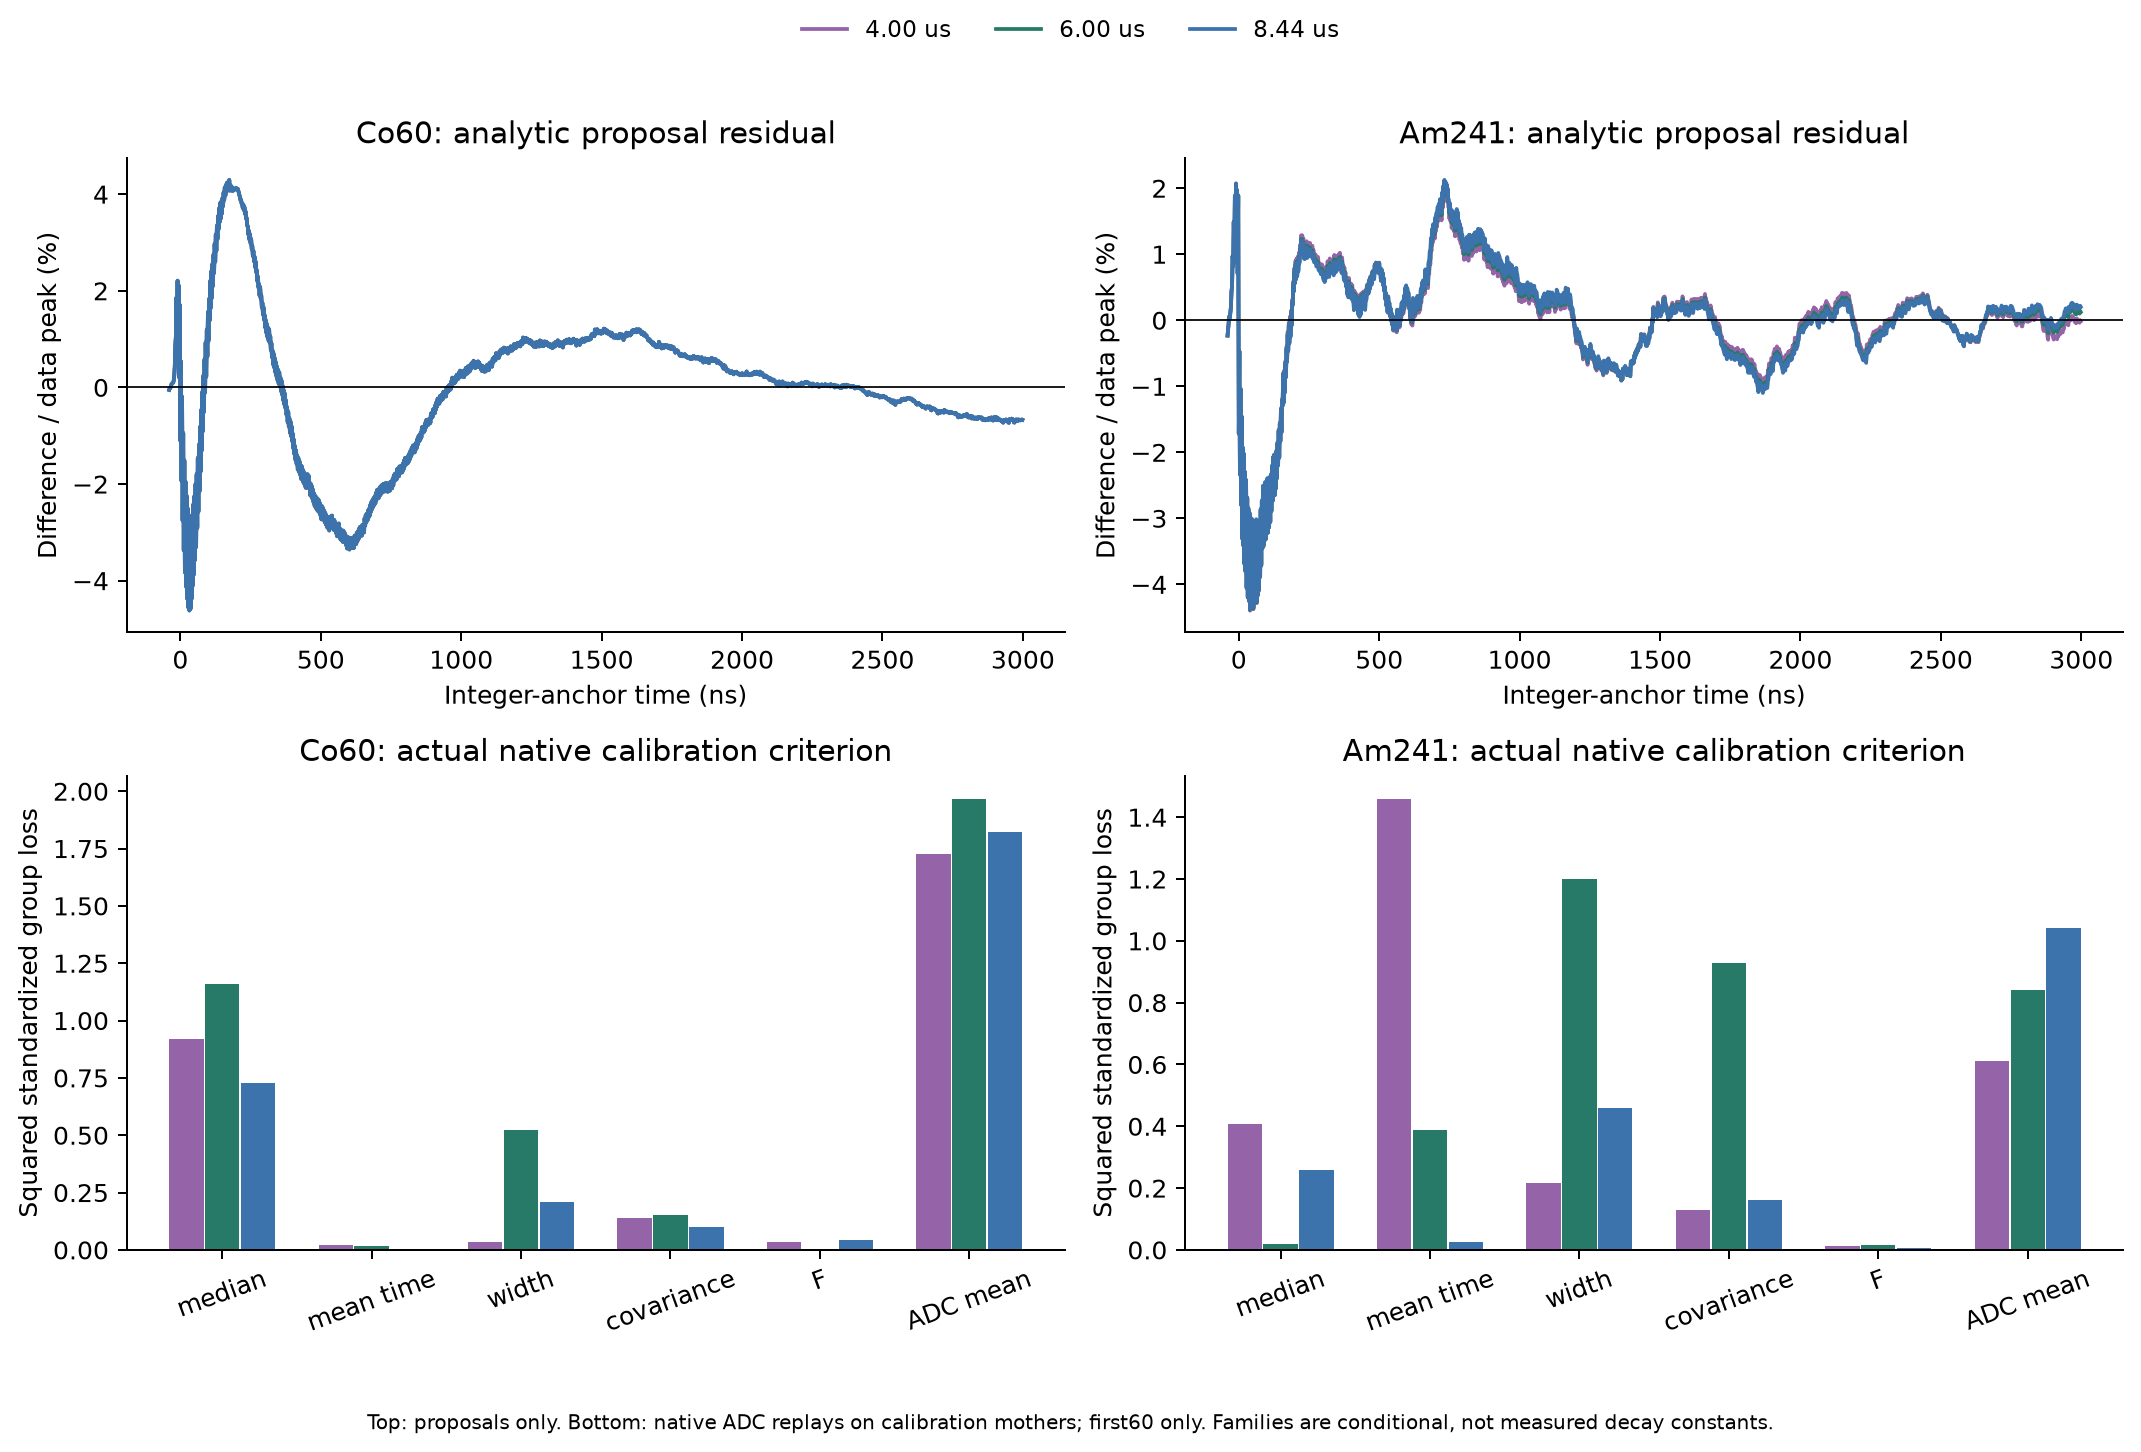

In [2]:
rows=[]
for family,slow in d['families_alpha_slow_ns'].items():
    fit=read(OUT/'fit'/f'{family}.json');p=fit['best']['parameters']
    c=read(OUT/'profile'/f'{family}_run12_Am241/config.json')
    rows.append([family,f'{slow/1000:.4f}',nums(p['electron_tau_ns']),f"{p['alpha_tau_ns'][0]:.2f}",
        f"{p['lowpass_ns']:.2f}",f"{c['optical']['alpha_light_yield_ratio']:.4f}",f"{fit['best']['objective']:.4f}"])
display(Markdown(table(['组','α慢τ/μs','电子τ/ns','α快τ/ns','共同RC/ns','有效α相对归一化','解析目标'],rows)))
proposal=dict(np.load(OUT/'proposal_curves.npz'))
for source in ['Co60','Am241']:
    delta=proposal['a4000__'+source]-proposal['a8439__'+source]
    peak=proposal[source+'_data'].max()
    print(source,'4与8.44 μs提议曲线之间的NRMSE/实测峰:',f'{100*np.sqrt(np.mean(delta**2))/peak:.4f}%')
display(Image(filename=str(OUT/'figures/joint_family_profile.png')))

## 2. 在每组原生光学历史上重新拟合噪声

校准输运先关闭信号期经验残差，保留光子统计、SiPM和原前触发电子噪声。
用前60%的三种PID完整3×3协方差、F50/F102/F202三个起伏均值，拟合非负的功率谱混合：继承谱、白噪声、20/60/150/400/1000/2500 ns指数相关核。
合成1025点FIR核，再重估其非负强度；事件方差CV沿用原值。

协方差提议使用固定锚点线性化，F提议使用16组高斯创新的二次矩期望。**拟合预测本身不是验证结果**：随后由C++重新生成噪声、量化ADC、求自己的锚点与积分门，并重做原质量/Q选择。
实测协方差在每Q箱按中位数±3 IQR/1.349截尾，模拟协方差不截尾；IQR另行按原分位数计算。

本轮核查捕获一条 t₁₀ 恰好位于整数样点的事件：用 `anchor−0.5` 代替真实 t₁₀ 会使F统计窗口错开一个样点。
已在本轮拟合中改用实际分数t₁₀，核对全部六组原生ADC，并重算所有噪声拟合；正式PID整数积分门不变。
修正前的中间拟合和失败日志保留在 `diagnostics/anchor_proxy_before_fix`，以前冻结的研究目录保持不变。

带宽包括有限光子数、波形形状、相关残差和采集状态等影响。仅调整前触发RMS不足以解释完整协方差。
这里拟合的是有效的、采集状态相关的随机响应，尚未确定其唯一微观来源。


In [3]:
rows=[]
for family in d['families_alpha_slow_ns']:
    for run,source in [(3,'Co60'),(12,'Am241')]:
        key=f'{family}_run{run}_{source}';f=read(OUT/'noise_fit'/f'{key}.json')
        active=[f'{n}:{v:.3g}' for n,v in zip(f['components'],f['component_variances']) if v>1e-9]
        rows.append([key,f['n_MC'],f"{f['variance_per_signal_adc']:.4f}",nums(f['predicted_SD_ratio']),nums(f['predicted_F_ratio']),'; '.join(active)])
display(Markdown(table(['组','校准共同Q数','信号方差强度','预测SD比','预测F比','非零谱分量/功率'],rows)))
audit=read(OUT/'diagnostics/anchor_boundary_audit.json')
print('实际t10回归检查事件数:',sum(x['events_checked'] for x in audit['arrays'].values()))
print('半采样近似影响的原事件ID:',{k:v['affected_original_event_ids'] for k,v in audit['arrays'].items() if v['affected_original_event_ids']})
print('原生噪声重放保留同一母事件和雪崩历史；计数不翻倍。')

实际t10回归检查事件数: 1398
半采样近似影响的原事件ID: {'a8439_run3_Co60': [3302]}
原生噪声重放保留同一母事件和雪崩历史；计数不翻倍。


|组|校准共同Q数|信号方差强度|预测SD比|预测F比|非零谱分量/功率|
|---|---|---|---|---|---|
|a4000_run3_Co60|293|0.4928|1.020 / 0.916 / 0.987|1.004 / 1.014 / 0.991|white:0.000639; exp_20ns:0.142; exp_60ns:0.269; exp_2500ns:0.0959|
|a4000_run12_Am241|189|2.8432|0.992 / 0.977 / 0.979|1.010 / 1.003 / 1.014|inherited_spectrum:2.76; exp_20ns:0.00603; exp_400ns:0.0135; exp_2500ns:0.0768|
|a6000_run3_Co60|306|0.4750|0.986 / 0.934 / 1.010|1.003 / 1.007 / 0.997|white:0.00296; exp_20ns:0.13; exp_60ns:0.279; exp_2500ns:0.0729|
|a6000_run12_Am241|183|2.8392|0.990 / 0.975 / 0.980|1.010 / 1.003 / 1.014|inherited_spectrum:2.66; exp_20ns:0.0101; exp_60ns:0.0403; exp_400ns:0.107; exp_2500ns:0.0385|
|a8439_run3_Co60|252|0.4870|1.008 / 0.900 / 1.005|1.006 / 1.012 / 0.993|exp_20ns:0.145; exp_60ns:0.253; exp_2500ns:0.106|
|a8439_run12_Am241|175|2.8960|0.996 / 0.983 / 0.980|1.008 / 1.001 / 1.015|exp_20ns:0.046; exp_60ns:0.662; exp_150ns:2.1; exp_2500ns:0.0907|

## 3. 冻结的联合判据与新种子检验

各源等权，以下六组标准化平方残差各取组内均值后相加：

- 三个PID中位数偏差/实验IQR，尺度0.20；
- 平均时间均值差，尺度3 ns；
- 三个IQR比相对1的偏差，尺度0.15；
- 协方差上三角六项偏差/实验SD乘积，尺度0.25；
- 三个F比相对1的偏差，尺度0.10；
- 未缩放均ADC的NRMSE，尺度0.01。

这些是预先冻结的描述性权重，指标彼此相关，**不是独立误差或卡方检验**。
只按前60%校准重放的最小联合目标选组。下面同时展示三组训练表现和选中组的新种子前60%检查；有限MC可能影响排名，不能据此宣称α慢τ被唯一测定。


In [4]:
rows=[]
for family,case in s['ranking'].items():
    for source,a in case['sources'].items():
        rows.append([family,source,'校准',f"{a['objective']:.3f}",f"{a['mean_time_difference_ns']:+.3f}",nums(a['IQR_ratio']),nums(a['F_ratio']),f"{100*a['mean_ADC_NRMSE']:.3f}%"])
for run,source in [(3,'Co60'),(12,'Am241')]:
    a=r['checks'][f'run{run}_first60']['models']['joint']['joint_criterion_check']
    rows.append([s['selected_family'],source,'新种子',f"{a['objective']:.3f}",f"{a['mean_time_difference_ns']:+.3f}",nums(a['IQR_ratio']),nums(a['F_ratio']),f"{100*a['mean_ADC_NRMSE']:.3f}%"])
display(Markdown(table(['组','源','用途','联合目标','平均时间差/ns','QDC/时间/PCA宽度比','F50/102/202比','均ADC NRMSE'],rows)))
print('在新种子运行前已冻结选组:',s['selected_family'])
print('各组两源平均目标:',{k:round(v['objective'],4) for k,v in s['ranking'].items()})

在新种子运行前已冻结选组: a8439
各组两源平均目标: {'a4000': 2.8565, 'a6000': 3.6106, 'a8439': 2.4248}


|组|源|用途|联合目标|平均时间差/ns|QDC/时间/PCA宽度比|F50/102/202比|均ADC NRMSE|
|---|---|---|---|---|---|---|---|
|a4000|Co60|校准|2.878|+0.438|0.987 / 0.964 / 0.971|0.985 / 0.995 / 0.972|1.314%|
|a4000|Am241|校准|2.835|+3.625|1.092 / 0.926 / 1.026|1.012 / 1.008 / 1.012|0.782%|
|a6000|Co60|校准|3.824|-0.406|0.879 / 0.891 / 0.906|0.996 / 1.004 / 1.004|1.403%|
|a6000|Am241|校准|3.397|+1.872|0.825 / 0.977 / 0.777|1.015 / 0.987 / 0.989|0.918%|
|a8439|Co60|校准|2.899|+0.026|0.890 / 1.037 / 1.024|1.030 / 1.019 / 0.994|1.349%|
|a8439|Am241|校准|1.950|+0.484|0.976 / 0.856 / 0.902|1.000 / 0.988 / 0.999|1.021%|
|a8439|Co60|新种子|3.277|+0.172|0.937 / 0.921 / 1.042|0.991 / 0.993 / 0.970|1.352%|
|a8439|Am241|新种子|3.507|+2.154|1.170 / 1.040 / 1.236|1.017 / 0.999 / 0.986|0.980%|

另做512次**仅针对MC统计量**的排名稳定性检查：固定原实验前60%目标和已经拟合的参数，各组分别对完整母事件重采样，再计算同一联合目标。
此检查不改变已冻结的选择，不读取新验证数据，也没有重新拟合噪声。表中“第一名频率”仅说明有限MC下的排名敏感性，**不是模型后验概率**，未包括实验、拟合或装置不确定性。

In [5]:
stability=read(OUT/'ranking_stability.json')
rows=[]
for family,a in stability['results'].items():
    rows.append([family,f"{a['point_objective']:.3f}",f"{100*a['rank1_frequency']:.1f}%",nums(a['bootstrap_objective_p025_p50_p975']),nums(a['objective_minus_selected_CI95'])])
display(Markdown(table(['组','原目标','重采样第一名频率','目标2.5/50/97.5分位','相对选中组目标差95%范围'],rows)))
print('有效重采样:',stability['valid_resamples'],'/ 512；已冻结选择改变:',stability['saved_selection_changed'])

有效重采样: 512 / 512；已冻结选择改变: False


|组|原目标|重采样第一名频率|目标2.5/50/97.5分位|相对选中组目标差95%范围|
|---|---|---|---|---|
|a4000|2.857|36.5%|2.191 / 3.607 / 8.398|-2.242 / 5.082|
|a6000|3.611|10.0%|2.939 / 4.417 / 6.832|-1.739 / 3.897|
|a8439|2.425|53.5%|2.351 / 3.336 / 5.736|0.000 / 0.000|

## 4. 完整Geant4输出的均ADC波形

实际ADC逐事件扣基线、按t₁₀对齐，在原Q支持箱内取均值后箱间等权；模拟不重新缩放峰值。
NRMSE为−40至3000 ns均方根差除以实测均波形峰值。
保留较早光子统计候选和上一轮尾部候选作描述性参照，并列展示两种源与三个实验段，不能只选择吻合的波段。
图额外展示3–3.8 μs阴影区：这部分没有参与本轮拟合或排名，仅作选组后的外推诊断，不据此修改本轮参数。
额外尾电荷为分数t₁₀对齐后3000≤t<3800 ns样点和除以原正式Qlong，不是归一化概率；这里只报告点估计，不附加等效性结论。


|实验段|模型|共同Q模拟数|门内均ADC NRMSE|均ADC峰比|额外尾NRMSE/总峰|额外尾电荷/Qlong差|
|---|---|---|---|---|---|---|
|run3_first60|npe|280|0.961%|1.0248|1.165%|-0.01037|
|run3_first60|tail|247|1.453%|1.0309|0.757%|-0.00668|
|run3_first60|joint|276|1.352%|1.0380|0.812%|-0.00715|
|run3_middle20|npe|280|0.983%|1.0264|1.154%|-0.01024|
|run3_middle20|tail|247|1.438%|1.0325|0.743%|-0.00655|
|run3_middle20|joint|276|1.355%|1.0396|0.798%|-0.00702|
|run3_last20|npe|280|0.957%|1.0262|1.124%|-0.00992|
|run3_last20|tail|247|1.429%|1.0323|0.714%|-0.00623|
|run3_last20|joint|276|1.336%|1.0394|0.769%|-0.00670|
|run12_first60|npe|206|1.129%|1.0250|0.297%|+0.00037|
|run12_first60|tail|194|0.793%|1.0151|0.570%|+0.00213|
|run12_first60|joint|194|0.980%|1.0081|1.087%|+0.00579|
|run12_middle20|npe|206|1.120%|1.0173|0.217%|-0.00036|
|run12_middle20|tail|194|0.848%|1.0075|0.482%|+0.00140|
|run12_middle20|joint|194|1.003%|1.0006|0.956%|+0.00507|
|run12_last20|npe|206|1.169%|1.0134|0.413%|+0.00214|
|run12_last20|tail|194|0.633%|1.0036|0.726%|+0.00391|
|run12_last20|joint|194|1.028%|0.9967|1.289%|+0.00757|

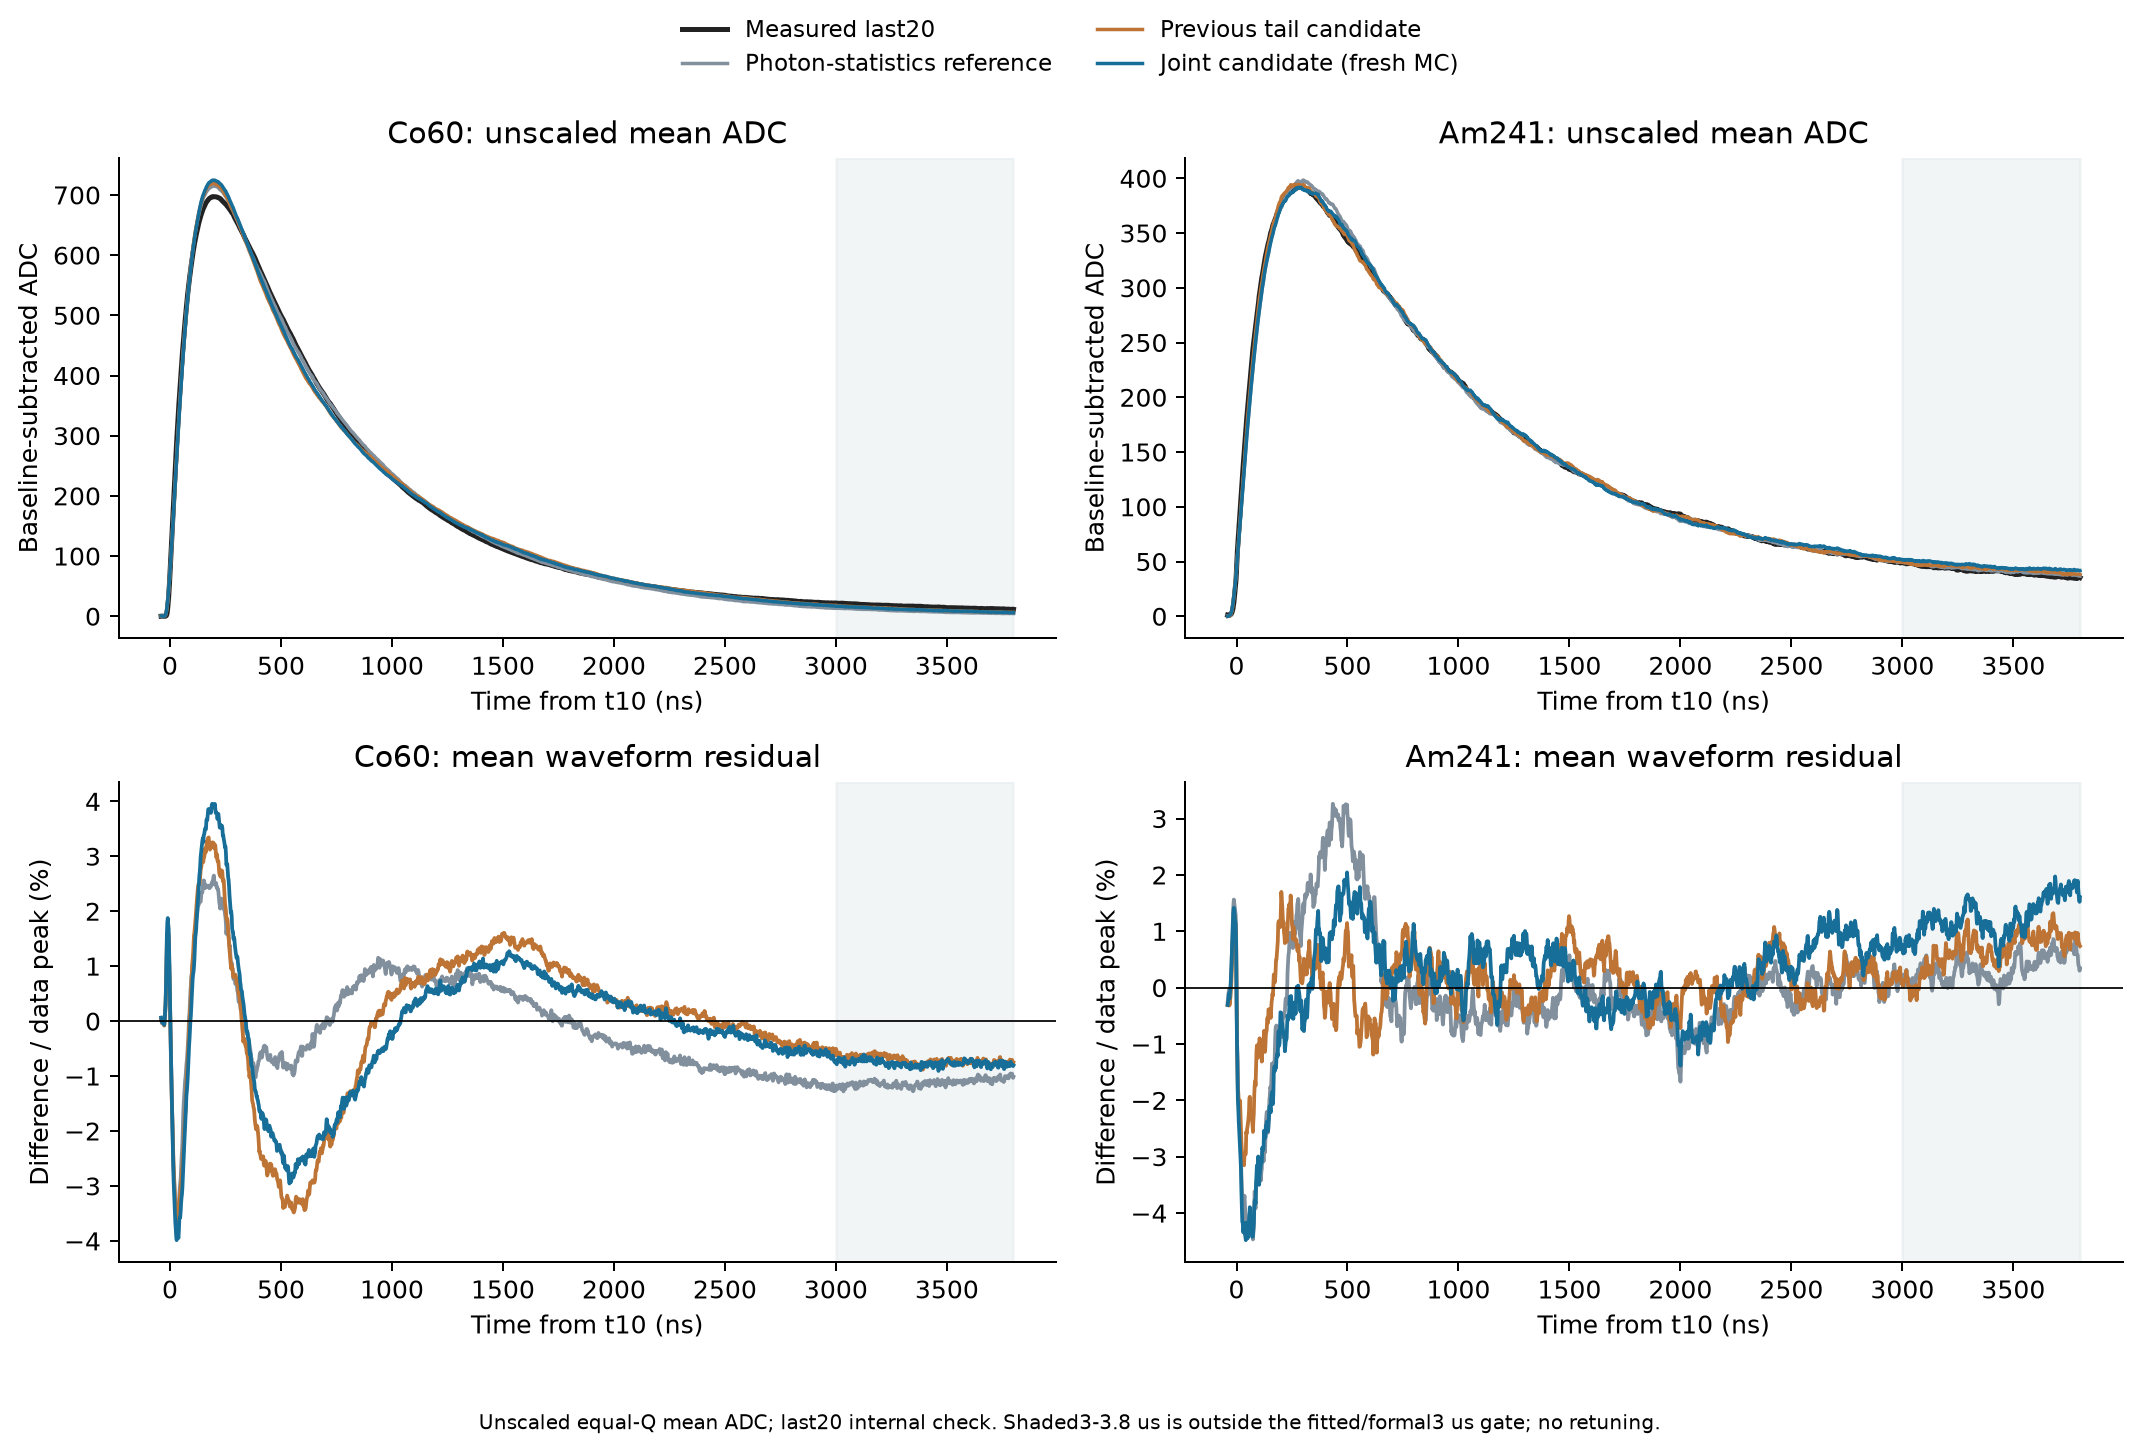

In [6]:
rows=[]
for group,c in r['checks'].items():
    for name,m in c['models'].items():
        extra=m['extended_tail_3000_3800_ns']
        rows.append([group,name,m['n_MC'],f"{100*m['mean_ADC_normalized_RMSE']:.3f}%",f"{m['mean_ADC_peak_ratio']:.4f}",
            f"{100*extra['ADC_NRMSE_over_full_peak']:.3f}%",f"{extra['difference']:+.5f}"])
display(Markdown(table(['实验段','模型','共同Q模拟数','门内均ADC NRMSE','均ADC峰比','额外尾NRMSE/总峰','额外尾电荷/Qlong差'],rows)))
display(Image(filename=str(OUT/'figures/joint_native_waveforms.png')))

## 5. PID中心与宽度必须同时检查

中心均值按正式整数锚点−40至3000 ns积分门计算；时间片的一阶矩共用每个事件的Qlong分母，片间求和严格等于正式平均时间。
宽度先在每个固定Q箱计算IQR，再对支持箱取RMS。run3使用6箱、run12使用前3箱。

区间使用512次整母事件重采样和实验原始序号块64/128重采样；旧MC和数据重采样保持上一轮冻结结果，新验证MC独立采样。
拟合、选组、装置和闭合修正均固定，未计入这些不确定性，未作多重比较校正。
前60%是训练数据检查，中/后段已经在此前研究中看过，**不是新实验盲验证**。


全部18组时间片贡献和通过正式平均时间核查。


|实验段|平均时间差/ns|95%区间|QDC/时间/PCA宽度比|时间宽度比CI/块64|CI/块128|
|---|---|---|---|---|---|
|run3_first60|+0.172|[-1.840, 2.173]|0.937 / 0.921 / 1.042|[0.798, 1.128]|[0.818, 1.134]|
|run3_middle20|-1.095|[-3.347, 1.052]|1.012 / 1.089 / 1.173|[0.883, 1.392]|[0.891, 1.410]|
|run3_last20|-0.160|[-2.636, 1.898]|1.030 / 0.927 / 1.037|[0.822, 1.215]|[0.806, 1.204]|
|run12_first60|+2.154|[-3.046, 7.309]|1.170 / 1.040 / 1.236|[0.825, 1.223]|[0.823, 1.211]|
|run12_middle20|+1.777|[-5.241, 8.008]|1.224 / 0.872 / 1.276|[0.665, 1.067]|[0.680, 1.063]|
|run12_last20|+7.216|[0.730, 13.789]|1.098 / 0.887 / 1.125|[0.689, 1.072]|[0.683, 1.046]|

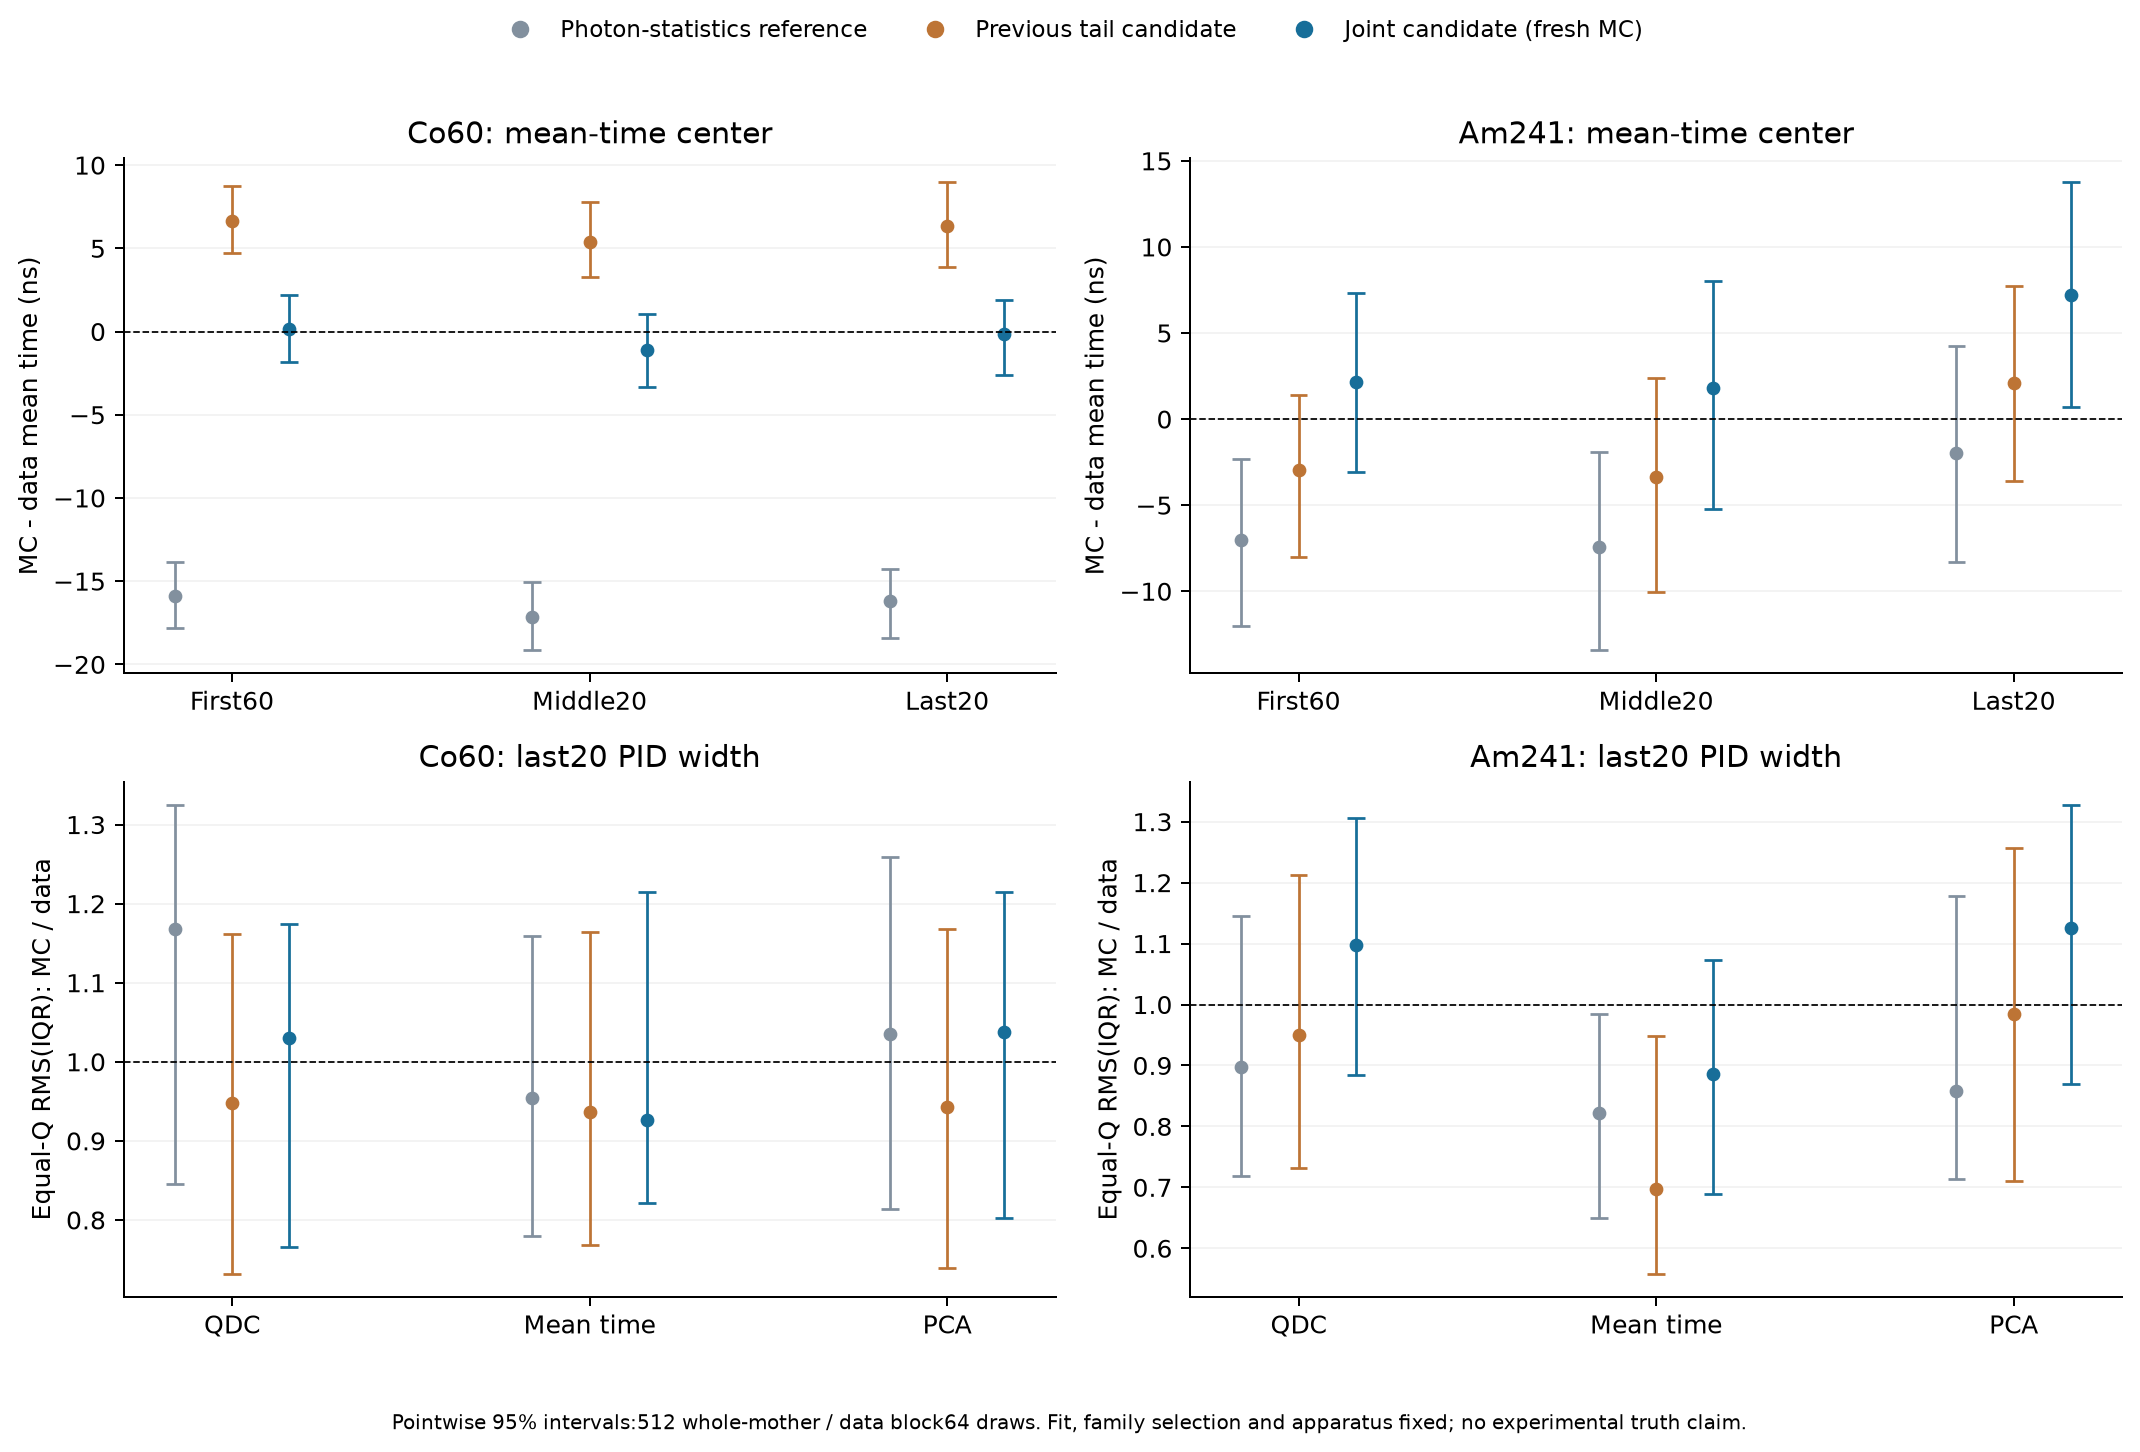

In [7]:
rows=[]
for group,c in r['checks'].items():
    m=c['models']['joint']
    rows.append([group,f"{m['tail_difference'][0]:+.3f}",ci(m,'tail_difference_CI95',0),nums(m['IQR_ratio']),
        ci(m,'IQR_ratio_CI95',1),ci(m,'IQR_ratio_CI95',1,'128')])
display(Markdown(table(['实验段','平均时间差/ns','95%区间','QDC/时间/PCA宽度比','时间宽度比CI/块64','CI/块128'],rows)))
display(Image(filename=str(OUT/'figures/joint_native_pid.png')))
for c in r['checks'].values():
    for m in c['models'].values():assert abs(sum(m['mean_time_slice_difference_ns'])-m['tail_difference'][0])<1e-8
print('全部18组时间片贡献和通过正式平均时间核查。')

## 6. 短尺度起伏和完整协方差

即使某一种PID宽度接近，也要检查另外两种及其相关性。下图同时展示F与协方差残差，保留未吻合项。
F是波形短尺度统计量，不是α接受率或γ泄漏率。本轮没有把两种源放到完全相同采集响应下重算ROC；不更新实验PID效率。
²⁴¹Am仍包含α、γ及衰变电子，实测主带诊断不是逐事件粒子真值。


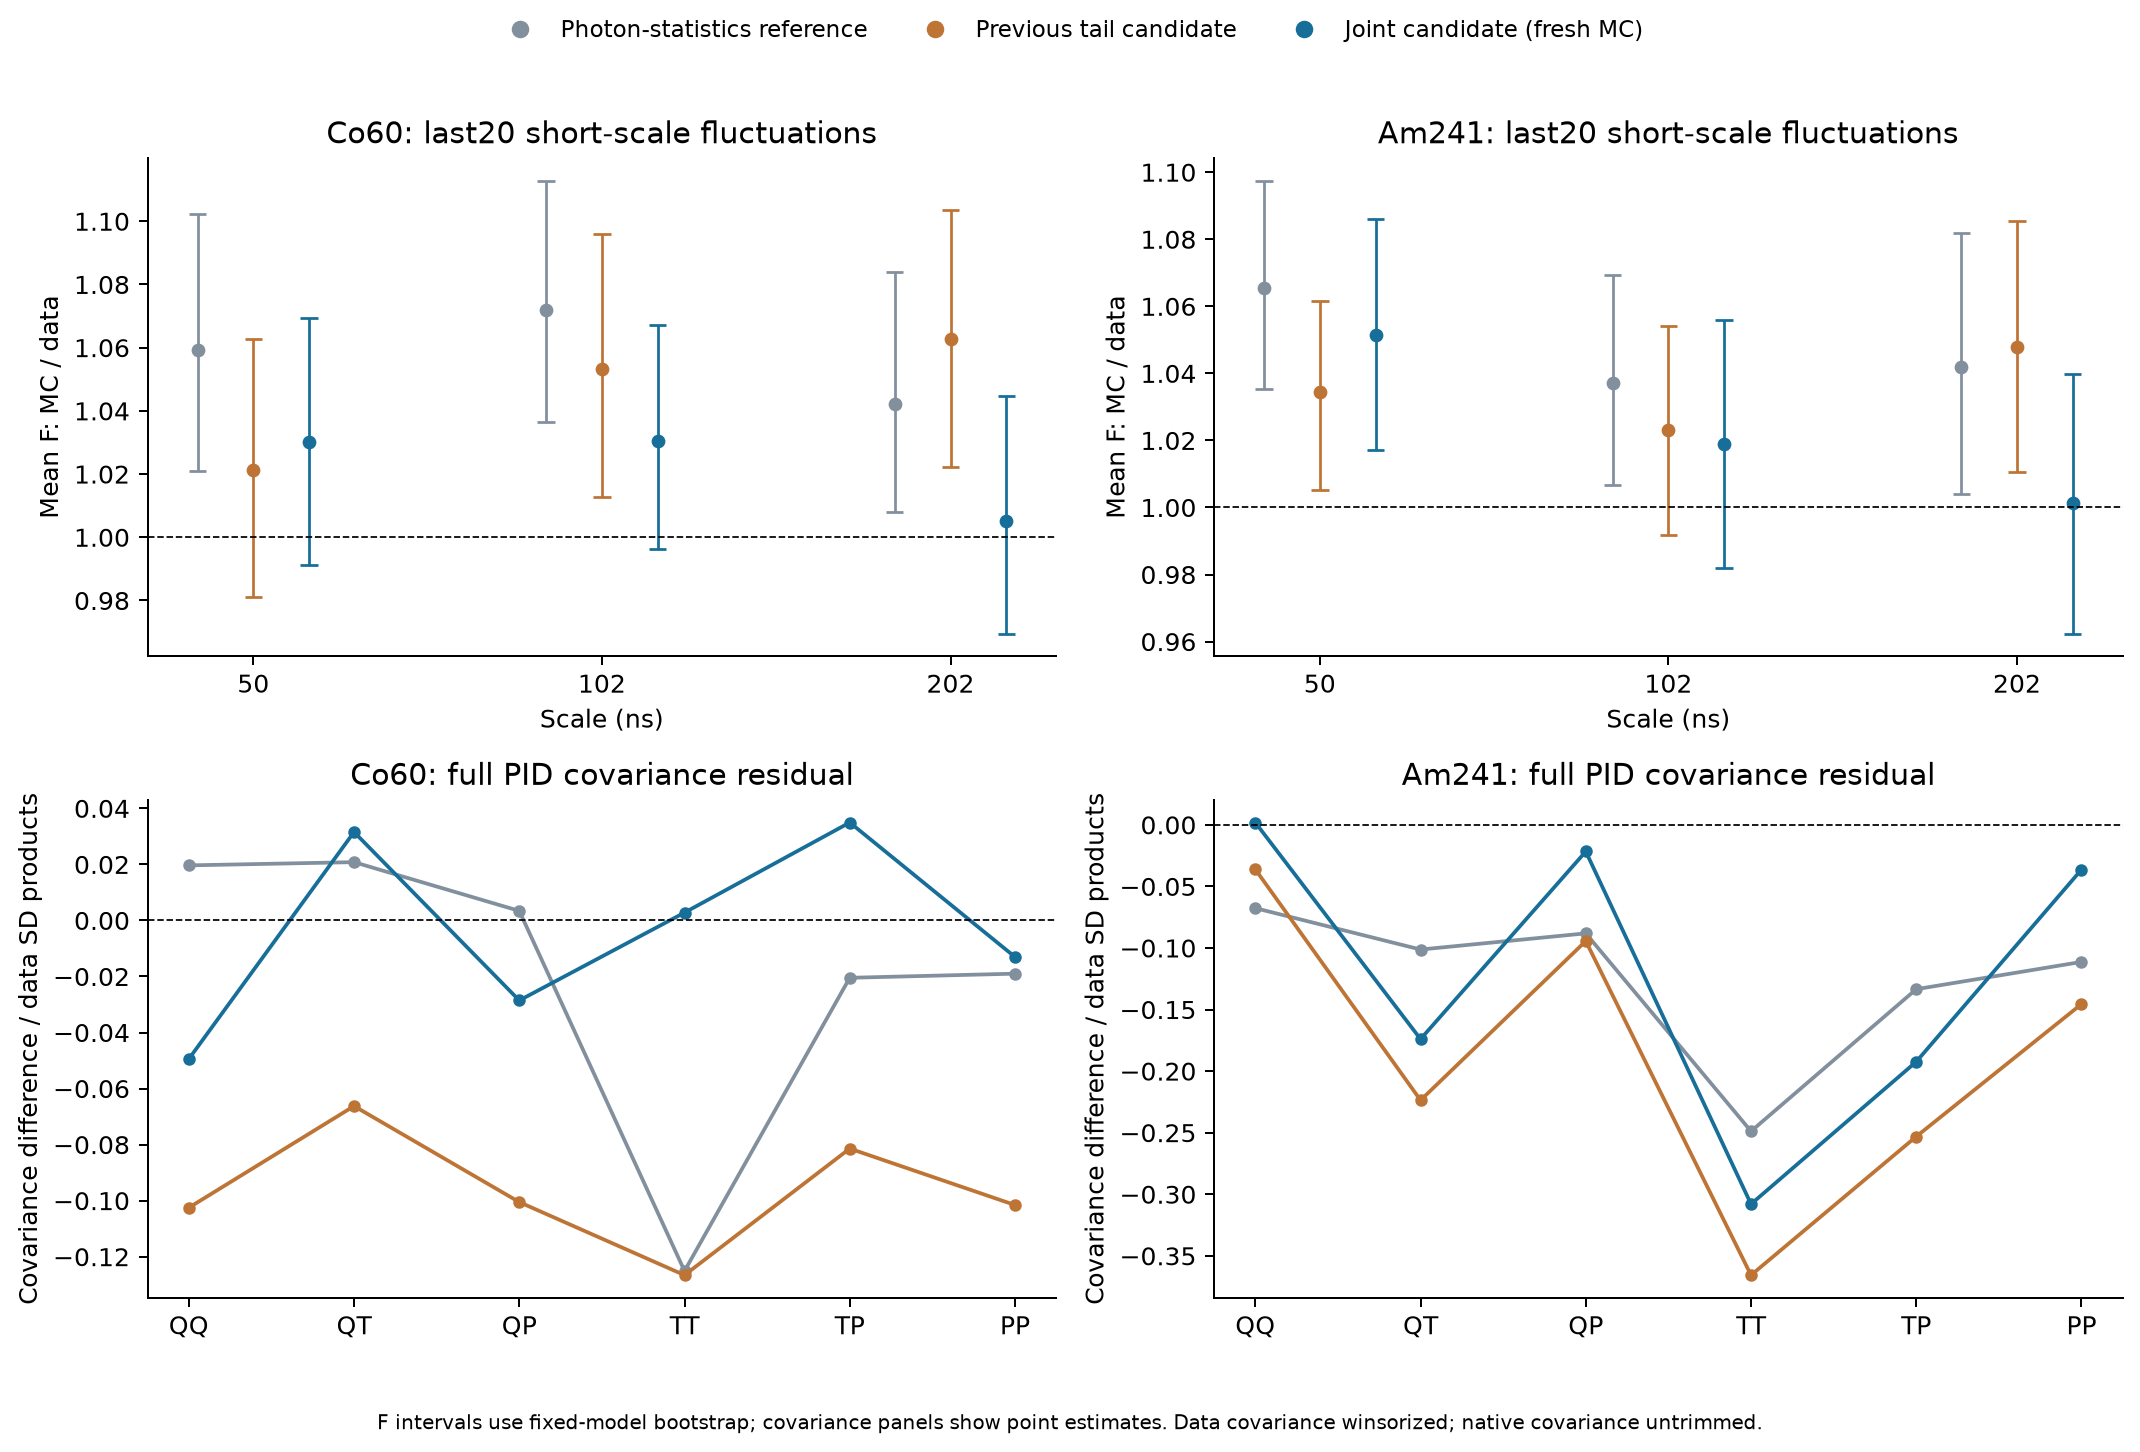

|源/后段|尺度/ns|F比|条件95%区间|
|---|---|---|---|
|Co60|50|1.0301|[0.991, 1.069]|
|Co60|102|1.0306|[0.996, 1.067]|
|Co60|202|1.0050|[0.970, 1.045]|
|Am241|50|1.0515|[1.017, 1.086]|
|Am241|102|1.0189|[0.982, 1.056]|
|Am241|202|1.0012|[0.962, 1.040]|

In [8]:
display(Image(filename=str(OUT/'figures/joint_noise_controls.png')))
rows=[]
for run,source in [(3,'Co60'),(12,'Am241')]:
    m=r['checks'][f'run{run}_last20']['models']['joint']
    for j,scale in enumerate([50,102,202]):rows.append([source,scale,f"{m['F_ratio'][j]:.4f}",ci(m,'F_ratio_CI95',j)])
display(Markdown(table(['源/后段','尺度/ns','F比','条件95%区间'],rows)))

逐Q箱再检查PID中位数和IQR，避免汇总比值掩盖电荷依赖。下图的竖线与阴影是分布四分位范围，不是均值或宽度的置信区间。
只画冻结支持箱，未对稀疏箱插值。

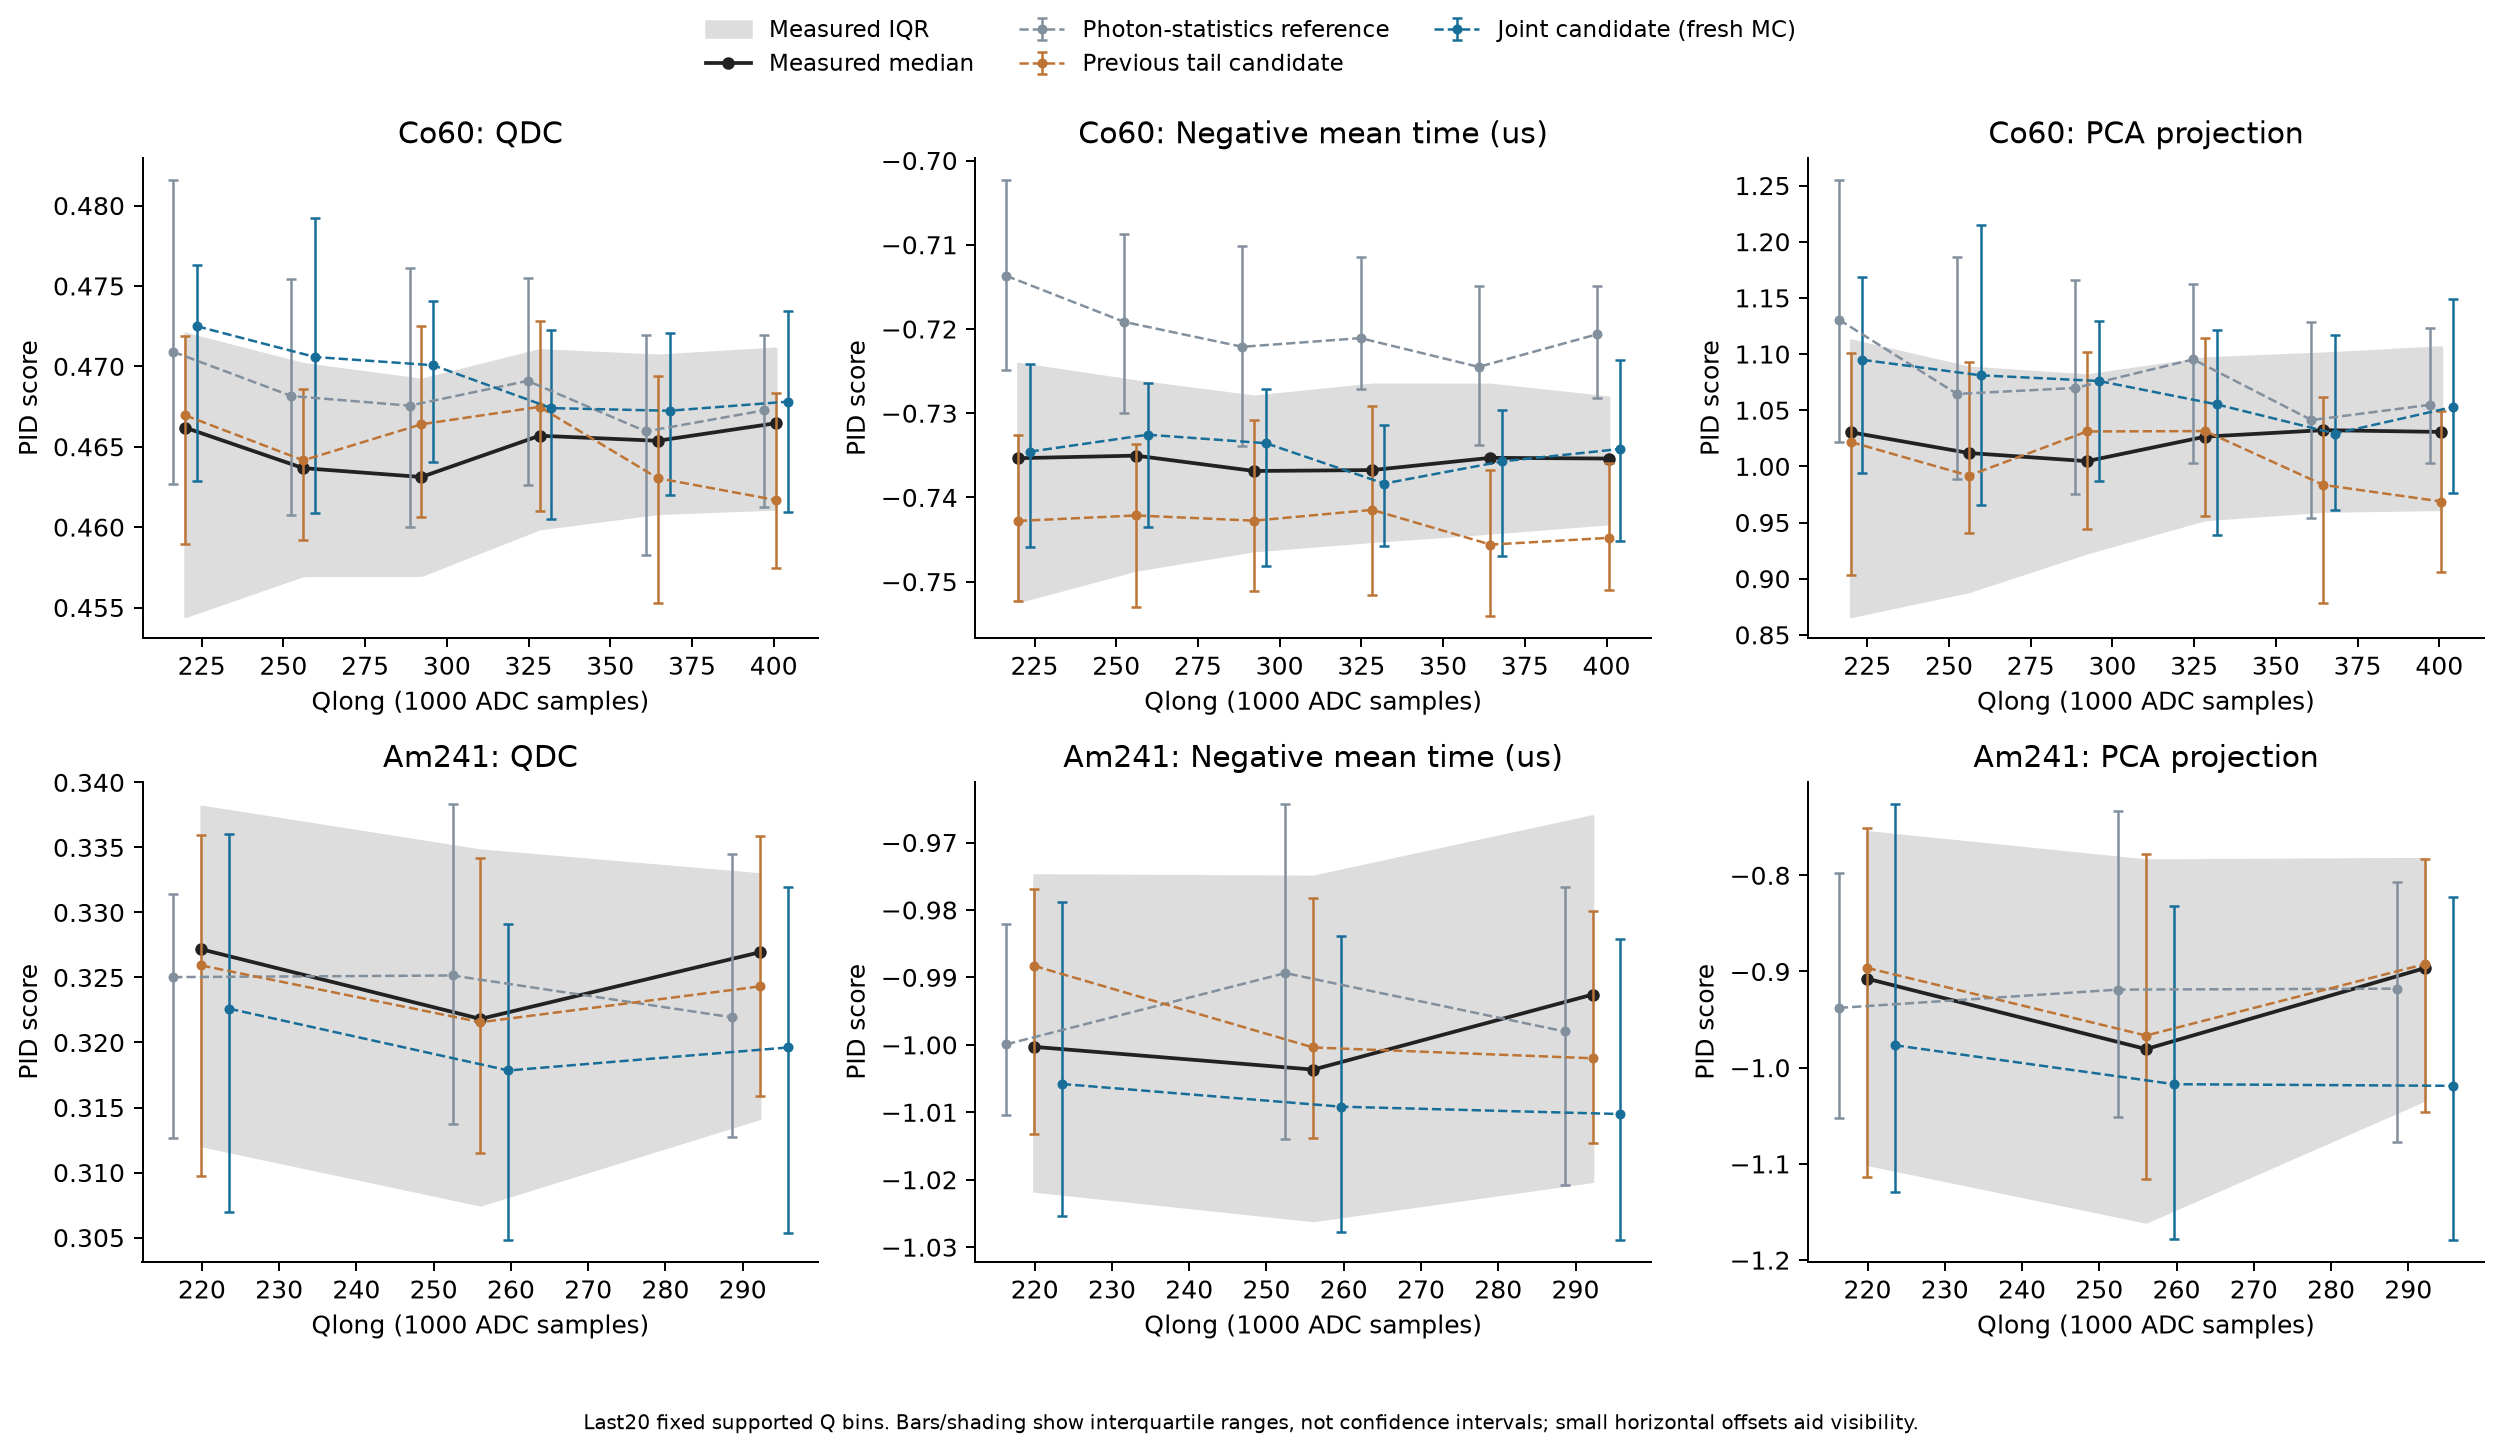

In [9]:
display(Image(filename=str(OUT/'figures/joint_pid_by_charge.png')))

## 7. 本轮结论与证据边界

选择、噪声配置和验证种子都在查看新验证结果前冻结，本轮不因后段表现再调整这份参数。
区间覆盖0或1不等于通过“完全一致”的等效性检验；有限MC、条件假设和参数退化仍需报告。
下表给出新的后段点估计及固定模型区间覆盖情况。默认配置没有自动替换。

若校准与新种子之间差异明显，应先量化有限MC影响，避免把随机宽度起伏当成材料τ信息。
若稳定残差集中在特定Q箱或中心/协方差方向，应检查响应模型的表达能力。
此前run12的噪声状态漂移继续作为单独对照保留；run18及同采集状态下两源PID转移尚未在本轮验证。

还要区分模拟偏差与实验段之间的变化：同一个固定模型对前/后段的中心残差之差，必然等于两段实测平均时间之差的相反数。
下面在相同固定Q箱、相同主带诊断下计算实测中/后段相对前60%的平均时间差，区间仅来自原实验块重采样。
这能提示固定响应跨段比较的限制，但不能单独把变化归因于温度、电路或某一种噪声；箱内电荷分布、选择和未记录状态也需要考虑。


In [10]:
rows=[]
for run,source in [(3,'Co60'),(12,'Am241')]:
    m=r['checks'][f'run{run}_last20']['models']['joint'];c=decision['last20_conditional_interval_checks'][source]
    rows.append([source,f"{m['tail_difference'][0]:+.3f}",f"{100*m['mean_ADC_normalized_RMSE']:.3f}%",nums(m['IQR_ratio']),
        c['mean_time_CI_contains_zero'],c['PID_width_CI_contains_one'],c['F_CI_contains_one']])
display(Markdown(table(['源','平均时间差/ns','均ADC NRMSE','三个宽度比','中心CI覆盖0','宽度CI覆盖1','FCI覆盖1'],rows)))
boot=dict(np.load(OUT/'bootstrap.npz'));changes=[]
for run,source in [(3,'Co60'),(12,'Am241')]:
    first=r['checks'][f'run{run}_first60']['data_tail_metrics'][0]
    for segment in ['middle20','last20']:
        delta=r['checks'][f'run{run}_{segment}']['data_tail_metrics'][0]-first
        cis=[]
        for block in [64,128]:
            v=boot[f'run{run}_{segment}__block{block}__moments'][:,0]-boot[f'run{run}_first60__block{block}__moments'][:,0]
            cis.append(nums(np.quantile(v[np.isfinite(v)],[.025,.975])))
        changes.append([source,segment,f'{delta:+.3f}',*cis])
display(Markdown(table(['实测源','实验段相对前60%','平均时间差/ns','块64区间/ns','块128区间/ns'],changes)))
print('α慢τ/ns:',decision['alpha_slow_ns'],'有效α相对归一化:',decision['alpha_relative_yield'])
print('默认配置已替换:',decision['promoted_to_default'])
print('复现：prepare_joint_constraints → run_joint_constraints profile → fit_joint_constraints → calibration replay → select_joint_constraints → fresh validation → analyze_joint_constraints → plot_joint_constraints')
print('核验/归档：simulation/verify_joint_constraints.py --archive')
print('表格：',OUT/'validation_table.csv')

α慢τ/ns: 8438.62820399502 有效α相对归一化: 0.99852321635028
默认配置已替换: False
复现：prepare_joint_constraints → run_joint_constraints profile → fit_joint_constraints → calibration replay → select_joint_constraints → fresh validation → analyze_joint_constraints → plot_joint_constraints
核验/归档：simulation/verify_joint_constraints.py --archive
表格： /media/sf_works/SiPM/simulation/results/joint_constraints_20261029/validation_table.csv


|源|平均时间差/ns|均ADC NRMSE|三个宽度比|中心CI覆盖0|宽度CI覆盖1|FCI覆盖1|
|---|---|---|---|---|---|---|
|Co60|-0.160|1.336%|1.030 / 0.927 / 1.037|True|[True, True, True]|[True, True, True]|
|Am241|+7.216|1.028%|1.098 / 0.887 / 1.125|False|[True, True, True]|[False, True, True]|

|实测源|实验段相对前60%|平均时间差/ns|块64区间/ns|块128区间/ns|
|---|---|---|---|---|
|Co60|middle20|+1.267|-0.434 / 2.852|-0.492 / 2.617|
|Co60|last20|+0.332|-1.330 / 1.971|-1.175 / 2.026|
|Am241|middle20|+0.377|-3.593 / 4.938|-3.936 / 4.970|
|Am241|last20|-5.062|-9.918 / -0.182|-9.990 / 0.431|